# 00 · Your first NexQus circuit / စတင်အသုံးပြုခြင်း

**Goal:** install NexQus, run a Bell circuit, and distinguish probabilities from sampled counts.
**Time:** about 10 minutes. No physics or GPU background is required.

NexQus ဖြင့် မိမိကွန်ပျူတာပေါ်တွင် quantum circuit ကို simulation လုပ်နိုင်ပါသည်။
စတင်ရန် quantum hardware သို့မဟုတ် GPU မလိုအပ်ပါ။

Open a terminal in the extracted SDK folder, activate your environment, and run:

```bash
python -m pip install --upgrade -e '.[tutorial]'
python -m ipykernel install --user --name nexqus --display-name "Python (NexQus)"
jupyter lab notebooks
```

Choose **Python (NexQus)** in Jupyter. Install commands belong in your terminal;
the code cells below contain plain Python, so they also work with the bundled runner.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nexqus
from nexqus import Circuit, Simulator, Parameter, Noise, NoiseModel, algorithms
assert tuple(map(int, nexqus.__version__.split('.')[:2])) >= (0, 6), 'Install this SDK with: python -m pip install -e .'
print('NexQus SDK:', nexqus.__version__)


NexQus SDK: 0.6.0


## Circuit → simulator → result

A circuit records operations. A simulator executes them. A result contains probabilities and sampled counts.
`q0` is the **leftmost** bit. `Circuit(2).x(0)` prepares `10`.

Circuit သည် gate အစဉ်ကို သိမ်းထားပြီး `run()` က တွက်ချက်ပေးပါသည်။
Bitstring ကို ဘယ်ဘက်မှ q0, q1, ... အစဉ်ဖြင့် ဖတ်ပါ။


In [2]:
q = Circuit(2).x(0)
result = Simulator().run(q, shots=100, seed=42)
print(result.counts)
assert result.counts == {'10': 100}


{'10': 100}


In [3]:
# H creates superposition; CX entangles the two qubits.
# qubit နှစ်ခုကို entangle လုပ်ပါ။
bell = algorithms.bell()
result = Simulator().run(bell, shots=1000, seed=42)
print('Probabilities:', result.probabilities)
print('Counts:', result.counts)
np.testing.assert_allclose(result.probabilities, [.5, 0, 0, .5], atol=1e-12)
assert set(result.counts) <= {'00', '11'}
assert sum(result.counts.values()) == 1000


Probabilities: [0.5 0.  0.  0.5]
Counts: {'00': 503, '11': 497}


Probabilities describe the simulated distribution. Counts fluctuate because we sample a finite number of shots.
More shots do not add qubits or make an approximate noise ensemble exact.
`seed` makes these draws repeatable under a fixed SDK/environment configuration.

Probability နှင့် count ကို ခွဲခြားကြည့်ပါ။ Count သည် random sampling ကြောင့် အနည်းငယ်ကွာနိုင်ပါသည်။


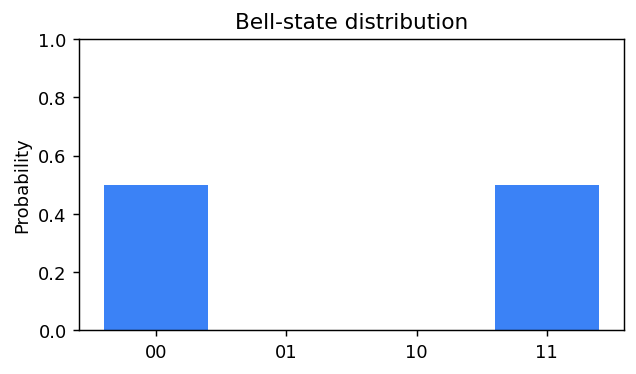

Checks passed. Next: 01_qubits_and_gates.ipynb


In [4]:
plt.figure(figsize=(5, 3))
plt.bar(['00', '01', '10', '11'], result.probabilities, color='#3b82f6')
plt.ylim(0, 1); plt.ylabel('Probability'); plt.title('Bell-state distribution')
plt.tight_layout(); plt.show()
print('Checks passed. Next: 01_qubits_and_gates.ipynb')


**Try it:** remove CX and inspect the bitstrings. Then change `shots` from 1000 to 100.
Predict which probabilities change and which differences are only sampling variation.
